<a href="https://colab.research.google.com/github/Chipurisandhyayadav/forest-fire-analysis/blob/main/analyse_forest_fire_frequency.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Forest Fire Frequency and Regional Impact Analysis
#
# Project ID: CBIT/IT-1/EDAV/2026/CEP-50
# Student Names: Chipuri Sandhya yadav,Harshini Suddala
# Roll Numbers: 160125737010,160125737055
# Department: Information Technology
# Institution: Chaitanya Bharathi Institute of Technology, Hyderabad
#
# Problem Statement:
# To analyze forest-fire frequency and its impact across different
# regions and seasons using Python data analysis and visualization.
#
# Overview:
# This project analyzes forest-fire frequency and estimated burned area.
# Pandas and NumPy are used for data processing, while Matplotlib and
# Seaborn are used for visualization.
#
# Dataset Link:
# Uploaded forest-fire dataset.
#
# Environment:
# Python, Pandas, NumPy, Matplotlib, Seaborn
#
# Objectives:
# 1. Calculate average fire incidence.
# 2. Filter fire records by region.
# 3. Handle missing fire records.
# 4. Group fire frequency by season and region.
# 5. Visualize fire frequency trends.
# Data Loading and Exploration
#
# Logic:
# Import the required libraries, upload the dataset, and load it into
# a Pandas DataFrame. Examine the structure, column names, summary
# statistics, and missing values.
#
# Syntax:
# files.upload() - Uploads the dataset.
# pd.read_excel() - Reads an Excel file.
# df.head() - Displays the first five rows.
# df.info() - Displays column information.
# df.describe() - Provides summary statistics.
# df.isna().sum() - Counts missing values.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Upload and load the Excel dataset
uploaded = files.upload()
file_name = next(iter(uploaded))
df = pd.read_excel(file_name)

print("Dataset loaded successfully.")
print("Rows and columns:", df.shape)

display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null values:")
df.info()

print("\nSummary statistics:")
display(df.describe())

print("\nMissing values:")
display(df.isna().sum())

Saving forest_fire_dataset_one_sheet.xlsx to forest_fire_dataset_one_sheet (1).xlsx
Dataset loaded successfully.
Rows and columns: (744, 10)


,Continent,Region,Ecosystem,Year,Month,Month_Number,Hemisphere_Season,Fire_Frequency_Count,Estimated_Burned_Area_km2,Impact_Level
0,North America,"California, USA",Temperate/Mediterranean,2024,January,1,Winter,4.0,63.0,Low
1,North America,"California, USA",Temperate/Mediterranean,2024,February,2,Winter,14.0,49.1,Low
2,North America,"California, USA",Temperate/Mediterranean,2024,March,3,Spring,24.0,349.8,Moderate
3,North America,"California, USA",Temperate/Mediterranean,2024,April,4,Spring,24.0,220.9,Low
4,North America,"California, USA",Temperate/Mediterranean,2024,May,5,Spring,25.0,307.5,Moderate



Column names:
['Continent', 'Region', 'Ecosystem', 'Year', 'Month', 'Month_Number', 'Hemisphere_Season', 'Fire_Frequency_Count', 'Estimated_Burned_Area_km2', 'Impact_Level']

Data types and non-null values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 744 entries, 0 to 743
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Continent                  744 non-null    object 
 1   Region                     744 non-null    object 
 2   Ecosystem                  744 non-null    object 
 3   Year                       744 non-null    int64  
 4   Month                      744 non-null    object 
 5   Month_Number               744 non-null    int64  
 6   Hemisphere_Season          744 non-null    object 
 7   Fire_Frequency_Count       737 non-null    float64
 8   Estimated_Burned_Area_km2  737 non-null    float64
 9   Impact_Level               744 non-null    object 
dtypes: float64

,Year,Month_Number,Fire_Frequency_Count,Estimated_Burned_Area_km2
count,744.0,744.000000,737.000000,737.000000
mean,2024.0,6.500000,26.632293,265.743419
std,0.0,3.454375,19.261196,248.221677
min,2024.0,1.000000,3.000000,8.000000
25%,2024.0,3.750000,12.000000,91.200000
50%,2024.0,6.500000,21.000000,183.900000
75%,2024.0,9.250000,37.000000,349.200000
max,2024.0,12.000000,106.000000,1711.800000



Missing values:


,0
Continent,0
Region,0
Ecosystem,0
Year,0
Month,0
Month_Number,0
Hemisphere_Season,0
Fire_Frequency_Count,7
Estimated_Burned_Area_km2,7
Impact_Level,0


In [ ]:
# Data Preparation
#
# Logic:
# Convert numerical columns into appropriate data types, create a
# date column using year and month, and arrange months in calendar order.
#
# Syntax:
# pd.to_numeric() - Converts values into numbers.
# pd.to_datetime() - Converts values into dates.
# pd.Categorical() - Creates ordered categories.
# .copy() - Creates a separate copy of the data.
# Convert numerical columns safely
numeric_cols = [
    "Year",
    "Month_Number",
    "Fire_Frequency_Count",
    "Estimated_Burned_Area_km2"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Create a date column
df["Date"] = pd.to_datetime(
    {
        "year": df["Year"],
        "month": df["Month_Number"],
        "day": 1
    },
    errors="coerce"
)

# Arrange months in calendar order
month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

df["Month"] = pd.Categorical(
    df["Month"].astype(str),
    categories=month_order,
    ordered=True
)

print("Prepared dataset:")
display(df.head())

Prepared dataset:


,Continent,Region,Ecosystem,Year,Month,Month_Number,Hemisphere_Season,Fire_Frequency_Count,Estimated_Burned_Area_km2,Impact_Level,Date
0,North America,"California, USA",Temperate/Mediterranean,2024,January,1,Winter,4.0,63.0,Low,2024-01-01
1,North America,"California, USA",Temperate/Mediterranean,2024,February,2,Winter,14.0,49.1,Low,2024-02-01
2,North America,"California, USA",Temperate/Mediterranean,2024,March,3,Spring,24.0,349.8,Moderate,2024-03-01
3,North America,"California, USA",Temperate/Mediterranean,2024,April,4,Spring,24.0,220.9,Low,2024-04-01
4,North America,"California, USA",Temperate/Mediterranean,2024,May,5,Spring,25.0,307.5,Moderate,2024-05-01


In [ ]:
# Q1: Calculate Average Fire Incidence
# Bloom's Level: BL-3 (Apply)
#
# Logic:
# Select the fire frequency column and calculate its mean to determine
# the average number of fires recorded in the dataset.
#
# Syntax:
# df["Fire_Frequency_Count"] - Selects the fire frequency column.
# .mean() - Calculates the average.
# print() - Displays the result.
# Calculate average fire frequency
average_fire_incidence = df["Fire_Frequency_Count"].mean()

print(
    f"Average fire incidence: "
    f"{average_fire_incidence:.2f}"
)

# Calculate average estimated burned area
average_burned_area = df["Estimated_Burned_Area_km2"].mean()

print(
    f"Average burned area: "
    f"{average_burned_area:.2f} km²"
)


Average fire incidence: 26.63
Average burned area: 265.74 km²


In [ ]:
# Q2: Filter Fire Data by Region
# Bloom's Level: BL-3 (Apply)
#
# Logic:
# Use Boolean indexing to select records belonging to a particular
# region and display the corresponding fire frequency and burned area.
#
# Syntax:
# df["Region"] == selected_region - Checks the selected region.
# df[condition] - Filters matching rows.
# .copy() - Creates an independent copy of the filtered data.
# Select a region that exists in the dataset
selected_region = "California, USA"

region_data = df[
    df["Region"].astype(str).str.strip()
    == selected_region
].copy()

# Display the selected region's data
print("Selected region:", selected_region)
print("Number of records:", len(region_data))

if region_data.empty:
    print("Region not found. Available regions:")
    print(df["Region"].dropna().unique())
else:
    display(
        region_data[
            [
                "Region",
                "Year",
                "Month",
                "Hemisphere_Season",
                "Fire_Frequency_Count",
                "Estimated_Burned_Area_km2"
            ]
        ]
    )

Selected region: California, USA
Number of records: 12


,Region,Year,Month,Hemisphere_Season,Fire_Frequency_Count,Estimated_Burned_Area_km2
0,"California, USA",2024,January,Winter,4.0,63.0
1,"California, USA",2024,February,Winter,14.0,49.1
2,"California, USA",2024,March,Spring,24.0,349.8
3,"California, USA",2024,April,Spring,24.0,220.9
4,"California, USA",2024,May,Spring,25.0,307.5
5,"California, USA",2024,June,Summer,42.0,382.0
6,"California, USA",2024,July,Summer,41.0,123.9
7,"California, USA",2024,August,Summer,32.0,387.4
8,"California, USA",2024,September,Autumn,14.0,245.4
9,"California, USA",2024,October,Autumn,53.0,766.1


In [ ]:
# Q3: Handle Missing Fire Records
# Bloom's Level: BL-4 (Analyze)
#
# Logic:
# Identify missing values in numerical columns and replace them with
# the respective column median in a separate cleaned DataFrame.
# The median is less affected by extreme values than the mean.
#
# Syntax:
# .isna().sum() - Counts missing values.
# .median() - Calculates the median.
# .fillna() - Replaces missing values.
# .copy() - Preserves the original dataset.
# Columns to clean
numeric_to_clean = [
    "Fire_Frequency_Count",
    "Estimated_Burned_Area_km2"
]

print("Missing values before cleaning:")
display(df[numeric_to_clean].isna().sum())

# Create a separate cleaned DataFrame
clean_df = df.copy()

for col in numeric_to_clean:
    median_value = clean_df[col].median()

    if pd.notna(median_value):
        clean_df[col] = clean_df[col].fillna(median_value)

print("Missing values after cleaning:")
display(clean_df[numeric_to_clean].isna().sum())

print("Original rows:", len(df))
print("Cleaned rows:", len(clean_df))

Missing values before cleaning:


,0
Fire_Frequency_Count,7
Estimated_Burned_Area_km2,7


Missing values after cleaning:


,0
Fire_Frequency_Count,0
Estimated_Burned_Area_km2,0


Original rows: 744
Cleaned rows: 744


In [ ]:
# Q4: Group Fire Incidences by Season and Region
# Bloom's Level: BL-4 (Analyze)
#
# Logic:
# Group the dataset by season and region and calculate the average
# fire frequency for each group. Sort the results to identify groups
# with the highest average fire frequency.
#
# Syntax:
# .groupby() - Groups records by categories.
# .mean() - Calculates the average.
# .reset_index() - Converts grouped output into a DataFrame.
# .sort_values() - Sorts the results.
# .head(10) - Displays the first ten records.
# Average fire frequency by season
season_summary = (
    clean_df.groupby(
        "Hemisphere_Season",
        dropna=False,
        observed=True
    )["Fire_Frequency_Count"]
    .mean()
    .reset_index(name="Average_Fire_Frequency")
    .sort_values(
        "Average_Fire_Frequency",
        ascending=False
    )
)

print("Average fire frequency by season:")
display(season_summary)

# Average fire frequency by region
region_summary = (
    clean_df.groupby("Region")["Fire_Frequency_Count"]
    .mean()
    .reset_index(name="Average_Fire_Frequency")
    .sort_values(
        "Average_Fire_Frequency",
        ascending=False
    )
)

print("Top 10 regions by average fire frequency:")
display(region_summary.head(10))

Average fire frequency by season:


,Hemisphere_Season,Average_Fire_Frequency
3,Summer,43.796296
1,Dry season (approx.),42.825000
0,Autumn,31.185185
4,Transition (approx.),29.375000
2,Spring,21.012346
5,Wet season (approx.),13.562500
6,Winter,10.030864


Top 10 regions by average fire frequency:


,Region,Average_Fire_Frequency
40,"Roraima, Brazil",39.333333
25,"Mato Grosso, Brazil",38.333333
28,"New South Wales, Australia",37.666667
19,Ghana northern region,37.500000
41,"Sabah, Malaysia",36.750000
3,Angola central highlands,35.500000
53,"Telangana, India",34.583333
26,"Miombo woodland, Zambia",33.833333
22,"Hokkaido, Japan",33.500000
24,"Madhya Pradesh, India",32.833333


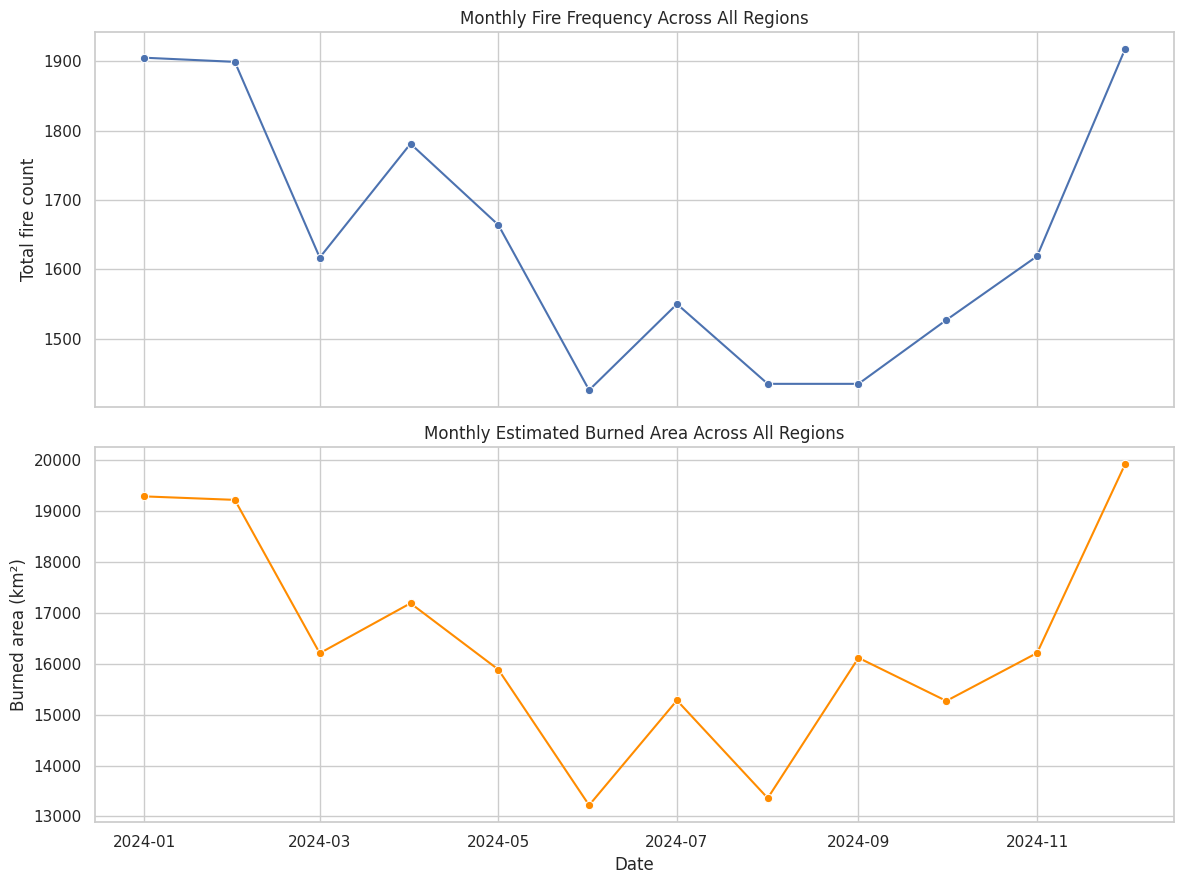

In [ ]:
# Q5: Visualize Fire Frequency Trends
# Bloom's Level: BL-5 (Evaluate)
#
# Logic:
# Visualize monthly fire frequency and estimated burned area using
# line plots. Use bar plots to compare average fire frequency across
# seasons and the ten highest-frequency regions.
#
# Syntax:
# plt.subplots() - Creates multiple plotting areas.
# .groupby() - Groups records.
# .agg() - Calculates aggregate values.
# sns.lineplot() - Displays trends over time.
# sns.barplot() - Compares categories.
# plt.show() - Displays the plots.
# Group data by date and calculate monthly totals
monthly_summary = (
    clean_df.dropna(subset=["Date"])
    .groupby("Date", as_index=False)
    .agg(
        Total_Fire_Frequency=(
            "Fire_Frequency_Count", "sum"
        ),
        Total_Burned_Area=(
            "Estimated_Burned_Area_km2", "sum"
        )
    )
    .sort_values("Date")
)

# Create two subplots
fig, axes = plt.subplots(
    2, 1, figsize=(12, 9), sharex=True
)

sns.lineplot(
    data=monthly_summary,
    x="Date",
    y="Total_Fire_Frequency",
    marker="o",
    ax=axes[0]
)

axes[0].set_title(
    "Monthly Fire Frequency Across All Regions"
)
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Total fire count")

sns.lineplot(
    data=monthly_summary,
    x="Date",
    y="Total_Burned_Area",
    marker="o",
    color="darkorange",
    ax=axes[1]
)

axes[1].set_title(
    "Monthly Estimated Burned Area Across All Regions"
)
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Burned area (km²)")

plt.tight_layout()
plt.show()

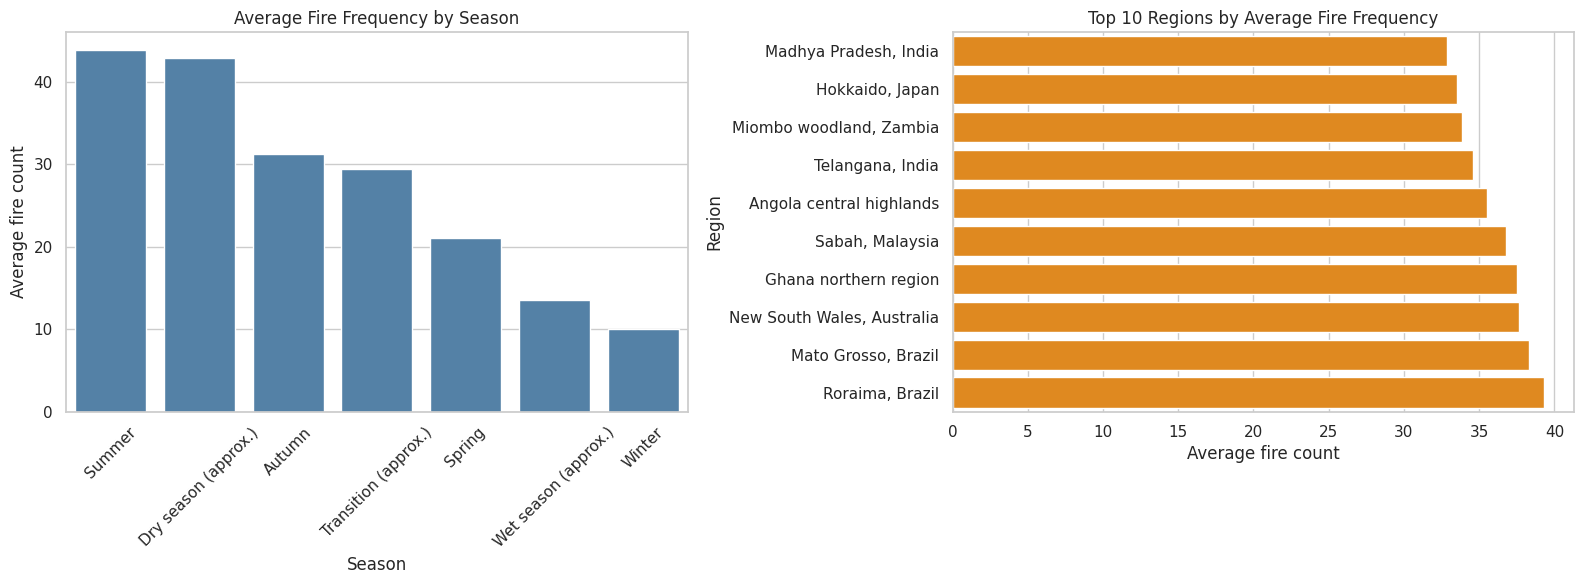

In [ ]:
# Create two side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(
    data=season_summary,
    x="Hemisphere_Season",
    y="Average_Fire_Frequency",
    color="steelblue",
    ax=axes[0]
)

axes[0].set_title("Average Fire Frequency by Season")
axes[0].set_xlabel("Season")
axes[0].set_ylabel("Average fire count")
axes[0].tick_params(axis="x", rotation=45)

# Select the ten highest-frequency regions
top10 = (
    region_summary.head(10)
    .sort_values("Average_Fire_Frequency")
)

sns.barplot(
    data=top10,
    x="Average_Fire_Frequency",
    y="Region",
    color="darkorange",
    ax=axes[1]
)

axes[1].set_title("Top 10 Regions by Average Fire Frequency")
axes[1].set_xlabel("Average fire count")
axes[1].set_ylabel("Region")

plt.tight_layout()
plt.show()

In [ ]:
# Conclusion
#
# This project analyzed forest-fire frequency and estimated burned
# area using Python. Average fire incidence was calculated, regional
# data was filtered, and missing numerical values were handled using
# median imputation.
#
# Grouping and visualization helped compare fire frequency across
# months, seasons, and regions. The analysis demonstrates how data
# analysis and visualization can identify patterns in forest-fire data.
#
# If the dataset is simulated, the findings represent patterns in the
# provided data rather than actual recorded forest-fire events.